# DiDeMo source exploration

This notebook examines every retained training and validation annotation: 23,202 training descriptions and 3,132 validation descriptions. Human temporal agreement describes annotation ambiguity, not model performance. The complete retained video cohort is covered separately in `04_full_corpus_encoding.ipynb`.

Run preparation first. Set `VIDEO_PREPARED` when the prepared directory is outside `data/processed/didemo-research-v5/prepared`. Test descriptions and temporal targets are not read here. This noncommercial availability cohort differs from the complete official benchmark.

In [1]:
import hashlib
import itertools
import json
import os
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "docs").is_dir():
    ROOT = ROOT.parent
PREPARED = Path(os.environ.get("VIDEO_PREPARED", ROOT / "data/processed/didemo-research-v5/prepared"))
FIGURES = ROOT / "docs/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
EXPECTED_MANIFEST = "ad99d633cee842d81a237dcd95e75f39edcf1589392963a3f5310fbf0cbda09b"

def sha(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()

assert sha(PREPARED / "manifest.json") == EXPECTED_MANIFEST
manifest = json.loads((PREPARED / "manifest.json").read_bytes())
data = {}
for split, expected_count in (("train", 23202), ("val", 3132)):
    name = split + ".json"
    assert sha(PREPARED / name) == manifest["files"][name]
    data[split] = json.loads((PREPARED / name).read_bytes())
    assert len(data[split]) == expected_count
assert sha(PREPARED / "media.json") == manifest["files"]["media.json"]
media = json.loads((PREPARED / "media.json").read_bytes())
geometry = {(row["split"], row["video"]): row["num_segments"] for row in media}
assert len(geometry) == 7454
display(pd.DataFrame([{ "split": split, "descriptions": len(rows), "unique_videos": len({r["video"] for r in rows})} for split, rows in data.items()]))

,split,descriptions,unique_videos
0,train,23202,5916
1,val,3132,797


## Description lengths and temporal labels

Lengths count whitespace-separated words. Annotated widths count inclusive five-second segment bins; the last bin can end before five seconds on a short clip. Repeated descriptions for the same canonical video remain separate examples.

In [2]:
records = []
all_ids = set()
for split, rows in data.items():
    for row in rows:
        assert row["id"] not in all_ids
        all_ids.add(row["id"])
        assert isinstance(row["text"], str) and row["text"].strip()
        segments = geometry[(split, row["video"])]
        assert len(row["times"]) >= 2
        for start, end in row["times"]:
            assert type(start) is int and type(end) is int
            assert 0 <= start <= end < segments
        records.append({
            "split": split,
            "words": len(row["text"].split()),
            "annotators": len(row["times"]),
            "mean_width_bins": sum(end - start + 1 for start, end in row["times"]) / len(row["times"]),
            "uses_alias": row["source_video"] != row["video"],
        })
frame = pd.DataFrame(records)
assert len(frame) == 26334
display(frame.groupby("split").agg(descriptions=("words", "size"), median_words=("words", "median"), mean_words=("words", "mean"), alias_descriptions=("uses_alias", "sum")))
display(pd.crosstab(frame["annotators"], frame["split"]).rename_axis("annotators_per_description"))

,descriptions,median_words,mean_words,alias_descriptions
split,,,,
train,23202,7.0,7.480519,143
val,3132,7.0,7.539591,55


split,train,val
annotators_per_description,,
4,23134,3121
5,1,0
7,67,11


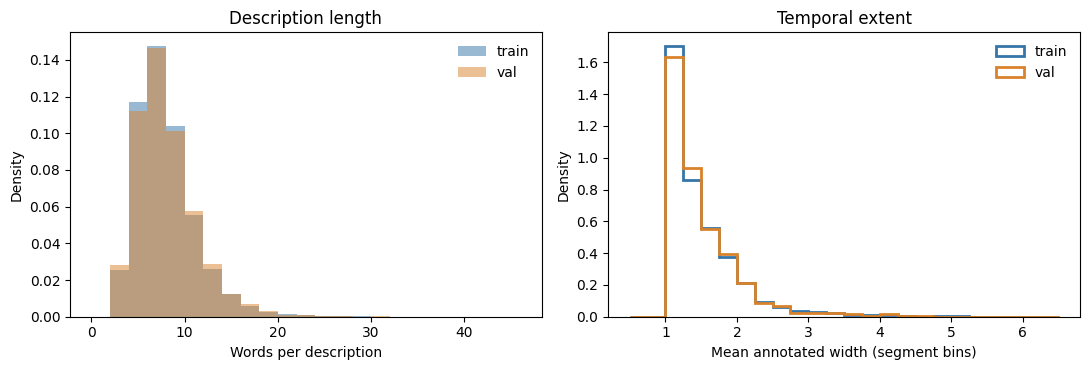

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
colors = {"train": "#3575a8", "val": "#d9822b"}
for split, group in frame.groupby("split", sort=False):
    axes[0].hist(group["words"], bins=range(0, int(frame["words"].max()) + 3, 2), density=True, alpha=0.5, label=split, color=colors[split])
    axes[1].hist(group["mean_width_bins"], bins=[0.5 + i * 0.25 for i in range(25)], density=True, histtype="step", linewidth=2, label=split, color=colors[split])
axes[0].set(xlabel="Words per description", ylabel="Density", title="Description length")
axes[1].set(xlabel="Mean annotated width (segment bins)", ylabel="Density", title="Temporal extent")
for axis in axes:
    axis.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "full-source-description-distributions.png", dpi=160)
plt.show()

## Agreement among human annotations

For each description, compute temporal intersection-over-union for every annotator pair, then average those pairs. This includes zero-overlap annotations. The calculation uses inclusive segment intervals, matching the retrieval task's interval convention. No model predictions enter this analysis.

,descriptions,mean_pairwise_iou,median_pairwise_iou,minimum_pairwise_iou
split,,,,
train,23202,0.743997,0.75,0.190476
val,3132,0.742992,0.75,0.333333


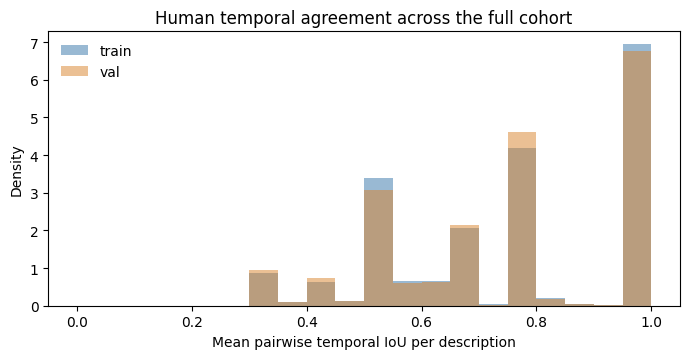

In [4]:
def temporal_iou(left, right):
    intersection = max(0, min(left[1], right[1]) - max(left[0], right[0]) + 1)
    union = (left[1] - left[0] + 1) + (right[1] - right[0] + 1) - intersection
    return intersection / union

agreement = []
for split, rows in data.items():
    for row in rows:
        values = [temporal_iou(a, b) for a, b in itertools.combinations(row["times"], 2)]
        agreement.append(sum(values) / len(values))
frame["pairwise_iou"] = agreement
assert frame["pairwise_iou"].between(0, 1).all()
agreement_summary = frame.groupby("split").agg(descriptions=("pairwise_iou", "size"), mean_pairwise_iou=("pairwise_iou", "mean"), median_pairwise_iou=("pairwise_iou", "median"), minimum_pairwise_iou=("pairwise_iou", "min"))
display(agreement_summary)
fig, axis = plt.subplots(figsize=(7, 3.7))
for split, group in frame.groupby("split", sort=False):
    axis.hist(group["pairwise_iou"], bins=[i / 20 for i in range(21)], density=True, alpha=0.5, label=split, color=colors[split])
axis.set(xlabel="Mean pairwise temporal IoU per description", ylabel="Density", title="Human temporal agreement across the full cohort")
axis.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "full-source-human-agreement.png", dpi=160)
plt.show()

## Query concentration

Some videos have more descriptions than others. Query-weighted retrieval metrics therefore weight those videos more heavily. This plot counts all retained descriptions per canonical video and preserves aliases in the query cohort.

,split,videos,minimum_queries,maximum_queries,median_queries
0,train,5916,1,10,4.0
1,val,797,1,9,4.0


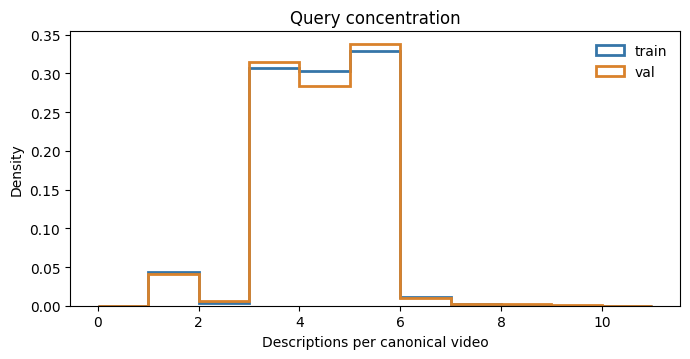

In [5]:
counts = {split: Counter(row["video"] for row in rows) for split, rows in data.items()}
display(pd.DataFrame([{ "split": split, "videos": len(values), "minimum_queries": min(values.values()), "maximum_queries": max(values.values()), "median_queries": float(pd.Series(values.values()).median())} for split, values in counts.items()]))
fig, axis = plt.subplots(figsize=(7, 3.7))
maximum = max(max(values.values()) for values in counts.values())
for split, values in counts.items():
    axis.hist(list(values.values()), bins=range(0, maximum + 2), density=True, histtype="step", linewidth=2, label=split, color=colors[split])
axis.set(xlabel="Descriptions per canonical video", ylabel="Density", title="Query concentration")
axis.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "full-source-query-concentration.png", dpi=160)
plt.show()

In [6]:
summary = {
    "schema": "full_video_source_eda_v1",
    "prepared_manifest_sha256": EXPECTED_MANIFEST,
    "input_sha256": {name: manifest["files"][name] for name in ("train.json", "val.json", "media.json")},
    "descriptions": len(frame),
    "test_descriptions_or_targets_read": False,
    "scope": "Complete retained training and validation query cohorts; no model score.",
    "splits": [],
}
for split, group in frame.groupby("split", sort=False):
    summary["splits"].append({
        "split": split,
        "descriptions": len(group),
        "unique_videos": len(counts[split]),
        "alias_descriptions": int(group["uses_alias"].sum()),
        "median_words": float(group["words"].median()),
        "maximum_words": int(group["words"].max()),
        "mean_words": float(group["words"].mean()),
        "annotator_counts": {str(k): int(v) for k, v in group["annotators"].value_counts().sort_index().items()},
        "mean_pairwise_iou": float(group["pairwise_iou"].mean()),
        "median_pairwise_iou": float(group["pairwise_iou"].median()),
        "mean_annotated_width_bins": float(group["mean_width_bins"].mean()),
        "maximum_queries_per_video": max(counts[split].values()),
    })
assert sha(PREPARED / "manifest.json") == EXPECTED_MANIFEST
for name, expected in summary["input_sha256"].items():
    assert sha(PREPARED / name) == expected
(ROOT / "docs/full-source-eda.json").write_text(json.dumps(summary, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print("Verified all 26,334 training and validation descriptions; saved aggregate analysis and three figures.")

Verified all 26,334 training and validation descriptions; saved aggregate analysis and three figures.


The annotation distributions explain part of the retrieval difficulty; they do not establish an achievable score or model improvement. Final model comparison and held-out evaluation are reported in the experiment and evaluation notebooks after their complete runs are verified.